# HEART Priority 2 | LNPDB × validated Ugi-4CR library

**One Jupyter Notebook. No separate `.sbatch` or `.py` files.**

### Execution guide

1. Upload this file as `HEART_LNPDB_Priority2_AllInOne.ipynb` into `/home/ypan/heart_liver/model_train/`.
2. **Recommended:** leave `RUN_MODE = "submit"`, then use **Kernel → Restart & Run All** once. This submits one independent Slurm job; the interactive notebook **does not** run the full audit. The Slurm job automatically switches to `analyze` mode.
3. **Alternative:** choose `RUN_MODE = "analyze"` to run the entire workflow within the existing Jupyter kernel (no Slurm submission). This mode can stop when the interactive session ends.
4. After submission, use the printed **Job ID** with `squeue` or `sacct`, and inspect `HEART_LNPDB_Priority2_Executed.ipynb` and `ugi_lnpdb_priority2_evidence/` when complete.

### Scientific sequence

**All unique LNPDB structures** → canonical RDKit identities → **exact lookup against the previously completed 15.18M Ugi SQLite index** → Ugi-like structural classification (not synthetic proof) → chemical diversity/scaffolds → publication-aware holdout proposal → representative ETKDG/MMFF 3D compatibility pilot → source-sampling scenarios → **nine-panel, publication-oriented figure (PNG, SVG, PDF)** and evidence-based integration report.

**Research boundaries:** No full 10-conformer LNPDB LMDB is generated. General-dataset overlap, authentic Ugi reagent reachability, and the production HEART three-source loader remain unverified. This Notebook does **not** modify the Ugi LMDB, LNPDB source CSV, the Priority 1 index, model checkpoints, or training weights.

**Important:** Do not use Jupyter Run All *and* an independent Slurm submission for the same notebook simultaneously. Successful Slurm execution is not automatic scientific permission to start training.

## 0 | Configuration and execution mode

`RUN_MODE = "submit"` is the **one-click batch mode**, with all Slurm parameters configured below. For an interactive run, set `RUN_MODE = "analyze"` and run the notebook directly. The environment variable `HEART_P2_BATCH_EXECUTION=1` overrides the setting *inside a Slurm job*, preventing recursive submissions.

In [1]:
# All paths, run switches, and Slurm resources are defined here.
from pathlib import Path
from argparse import Namespace
import os, sys

NOTEBOOK_FILE = "HEART_LNPDB_Priority2_AllInOne.ipynb"
EXECUTED_FILE = "HEART_LNPDB_Priority2_Executed.ipynb"
MODEL_TRAIN = Path(os.environ.get("HEART_MODEL_TRAIN_DIR", str(Path.cwd()))).expanduser().resolve()
PROJECT_ROOT = Path("/project/yli4/ypan")
LNPDB_CSV = PROJECT_ROOT / "lipid_library/input/LNPDB.csv"
UGI_MANIFEST = PROJECT_ROOT / "lipid_library/lmdb/manifest.json"
P1_AUDIT = MODEL_TRAIN / "ugi_priority1_interactive_evidence"
P2_RESULTS = MODEL_TRAIN / "ugi_lnpdb_priority2_evidence"

# Leave unset to automatically locate the completed Priority 1 molecular-identity index.
UGI_SQLITE_INDEX = os.environ.get("HEART_UGI_IDENTITY_DB") or None
PILOT_STRUCTURES_PER_GROUP = 20
PILOT_CONFORMERS_PER_STRUCTURE = 2
PILOT_WORKERS = 1  # Robust default for Jupyter and headless execution.
MAX_HEAVY_ATOMS = 256  # Screening only: not a proven HEART architecture cutoff.
RANDOM_SEED = 20261118

# Choose "submit" OR "analyze" (never both). Slurm forces analyze on execution.
RUN_MODE = "submit"
if os.environ.get("HEART_P2_BATCH_EXECUTION") == "1":
    RUN_MODE = "analyze"
assert RUN_MODE in {"submit", "analyze"}

SLURM_PARTITION = "medium"
SLURM_CPUS = 8
SLURM_MEMORY = "32G"
SLURM_WALLTIME = "08:00:00"

print("Execution mode:", RUN_MODE)
print("Notebook directory:", MODEL_TRAIN)
print("Notebook path:", MODEL_TRAIN / NOTEBOOK_FILE)
print("LNPDB input:", LNPDB_CSV, "| exists:", LNPDB_CSV.is_file())
print("Priority 1 full report:", P1_AUDIT / "03_full_molecular_audit.json")
print("Results directory:", P2_RESULTS)
print("Python interpreter:", sys.executable)


Execution mode: analyze
Notebook directory: /mnt/home/ypan/heart_liver/model_train
Notebook path: /mnt/home/ypan/heart_liver/model_train/HEART_LNPDB_Priority2_AllInOne.ipynb
LNPDB input: /project/yli4/ypan/lipid_library/input/LNPDB.csv | exists: True
Priority 1 full report: /mnt/home/ypan/heart_liver/model_train/ugi_priority1_interactive_evidence/03_full_molecular_audit.json
Results directory: /mnt/home/ypan/heart_liver/model_train/ugi_lnpdb_priority2_evidence
Python interpreter: /home/ypan/.conda/envs/py3_11/bin/python


## 1 | Submit one Slurm job from Jupyter (optional)

In `submit` mode, this cell **only submits** the job. Subsequent cells define functions but skip execution in your interactive kernel. A separate `.sbatch` file is not needed.

After submission, the notebook prints the job ID and the commands to check status. You may close the browser once Slurm accepts the job. In `analyze` mode, this cell does not submit anything.

In [2]:
# This cell submits a background Slurm job only in RUN_MODE="submit".
# The batch process sets HEART_P2_BATCH_EXECUTION=1, forcing RUN_MODE="analyze".
if RUN_MODE == "submit":
    import shutil, subprocess, shlex
    notebook_path = MODEL_TRAIN / NOTEBOOK_FILE
    if not notebook_path.is_file():
        raise FileNotFoundError(f"Upload the notebook using the exact name {NOTEBOOK_FILE}: {notebook_path}")
    if not LNPDB_CSV.is_file():
        raise FileNotFoundError(f"LNPDB CSV not found: {LNPDB_CSV}")
    if not (P1_AUDIT / "03_full_molecular_audit.json").is_file():
        raise FileNotFoundError("Priority 1 FULL report is missing; confirm P1_AUDIT before submitting.")
    if shutil.which("sbatch") is None:
        raise RuntimeError("sbatch command unavailable. Use RUN_MODE='analyze' in a compute-node Jupyter session.")
    wrap = (
        "set -e; "
        "export HEART_P2_BATCH_EXECUTION=1 PYTHONUNBUFFERED=1; "
        f"cd {shlex.quote(str(MODEL_TRAIN))}; "
        f"{shlex.quote(sys.executable)} -m jupyter nbconvert "
        f"--to notebook --execute {shlex.quote(NOTEBOOK_FILE)} "
        f"--output {shlex.quote(EXECUTED_FILE)} --ExecutePreprocessor.timeout=-1"
    )
    command = [
        "sbatch", "--parsable", "--job-name=heart-lnpdb-p2",
        f"--partition={SLURM_PARTITION}", "--nodes=1", "--ntasks=1",
        f"--cpus-per-task={SLURM_CPUS}", f"--mem={SLURM_MEMORY}",
        f"--time={SLURM_WALLTIME}",
        f"--output={str(MODEL_TRAIN / 'heart-p2-%j.out')}",
        f"--error={str(MODEL_TRAIN / 'heart-p2-%j.err')}",
        "--wrap", wrap,
    ]
    submission = subprocess.run(command, capture_output=True, text=True, cwd=MODEL_TRAIN)
    if submission.returncode != 0:
        raise RuntimeError("Slurm submission failed:\n" + submission.stderr.strip())
    job_id = submission.stdout.strip().split(";")[0]
    print(f"SUBMITTED: Slurm job {job_id}")
    print(f"Monitor: squeue -j {job_id}")
    print(f"Final status: sacct -j {job_id} --format=JobID,State,Elapsed,ExitCode,MaxRSS")
    print(f"Log: tail -n 50 {MODEL_TRAIN / ('heart-p2-' + job_id + '.out')}")
    print(f"Executed notebook after completion: {MODEL_TRAIN / EXECUTED_FILE}")
    print("You may close Jupyter after successful submission. Do not submit again.")
else:
    print("Direct analysis mode: no Slurm submission.")


Direct analysis mode: no Slurm submission.


## 2 | Scientific algorithms and publication-level graphics

All scientific analysis, QC, statistics, structural screening, reporting, and graphics are defined **in the following code cell**. No separate Python modules are required. Results and full chemical-data provenance are written only by the execution cell at the end.

In [3]:
# Priority 2 | all scientific methods in this notebook only
# The input library and all Priority 1 audit files are READ-ONLY.
# Exact identity uses the same RDKit canonical isomeric SMILES + BLAKE2b-128 policy as Priority 1.
# Substructure class is diagnostic; Ugi reagent compatibility is NOT proven by a motif.

"""Shared editorial figure settings for HEART Ugi-4CR / LNPDB validation.

Figures display measured input values only. Export PNG (300 dpi), SVG, and PDF.
"""
from pathlib import Path
import matplotlib as mpl
import matplotlib.pyplot as plt

COLORS = {
    "dark": "#344054", "muted": "#667085", "grid": "#E7E9EF",
    "ugi": "#D99A35", "ugi_light": "#F7DE9D", "ugi_deep": "#9D681A",
    "novel": "#B95860", "novel_light": "#F0B6A2", "novel_deep": "#883D56",
    "valid": "#557A79", "valid_light": "#A4C7BC",
    "neutral": "#A9AFB9", "background": "#FFFFFF",
}

def set_style():
    mpl.rcParams.update({
        "font.family": "DejaVu Sans", "font.size": 8.5,
        "axes.titlesize": 9.5, "axes.labelsize": 8,
        "xtick.labelsize": 7.5, "ytick.labelsize": 7.5,
        "legend.fontsize": 7.4,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.titleweight": "semibold", "axes.edgecolor": COLORS["grid"],
        "axes.labelcolor": COLORS["dark"], "text.color": COLORS["dark"],
        "xtick.color": COLORS["muted"], "ytick.color": COLORS["muted"],
        "axes.facecolor": "white", "figure.facecolor": "white",
        "grid.color": COLORS["grid"], "grid.alpha": 0.7,
        "svg.fonttype": "none", "pdf.fonttype": 42,
        "savefig.facecolor": "white", "savefig.dpi": 300,
    })

def label_panel(ax, letter):
    ax.text(-0.105, 1.085, letter, transform=ax.transAxes, fontweight="bold",
            fontsize=12, color="black", va="top", ha="left", clip_on=False)

def export(fig, destination: Path):
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    for ext in ("png", "svg", "pdf"):
        fig.savefig(destination.with_suffix("." + ext), dpi=300,
                    facecolor="white", bbox_inches="tight", pad_inches=0.15)
    plt.close(fig)
    return [str(destination.with_suffix("." + ext)) for ext in ("png", "svg", "pdf")]

C = COLORS


"""Priority-2 scientific add-ons: conservative synthesis assessment, source holdout,
source-weight simulations, and coherent multi-panel visualization.

All outputs are proposals/evidence. No LMDB, checkpoint, or training configuration is modified.
"""
import hashlib
import json
from collections import Counter, defaultdict
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import Draw, rdFingerprintGenerator
from rdkit.Chem.Scaffolds import MurckoScaffold
RDLogger.DisableLog('rdApp.*')

def _stable_bool(text, seed, fraction):
    raw=hashlib.sha256(f'{seed}|{text}'.encode('utf-8')).digest()
    return (int.from_bytes(raw[:8],'big')/2**64) < fraction

def _publication_holdout(csv_path, identities, seed=20261118, fraction=.2):
    """Group linked PMIDs into connected components to prevent cross-publication leakage.

    This is a proposed holdout, NOT a valid fully independent evaluation without
    provenance/General dataset review. Missing PMID is explicitly unresolved.
    """
    df=pd.read_csv(csv_path, usecols=['IL_SMILES','Publication_PMID'],
                   dtype=str,keep_default_na=False,low_memory=False)
    mol2pubs=defaultdict(set); cache={}
    for raw, pmid in zip(df['IL_SMILES'],df['Publication_PMID']):
        if raw not in cache:
            m=Chem.MolFromSmiles(raw.strip()) if isinstance(raw,str) and raw.strip() else None
            cache[raw]=Chem.MolToSmiles(m,canonical=True,isomericSmiles=True) if m else None
        can=cache[raw]
        if can in identities and pmid.strip():mol2pubs[can].add(pmid.strip())
    parent={}
    def find(x):
        parent.setdefault(x,x)
        while parent[x]!=x:
            parent[x]=parent[parent[x]];x=parent[x]
        return x
    def union(a,b):
        a,b=find(a),find(b)
        if a!=b:parent[max(a,b)]=min(a,b)
    for pset in mol2pubs.values():
        arr=sorted(pset)
        for x in arr[1:]:union(arr[0],x)
    return {s:('UNRESOLVED_PROVENANCE' if not mol2pubs[s] else
               'LNPDB_HOLDOUT_PROPOSED' if _stable_bool(find(sorted(mol2pubs[s])[0]),seed,fraction)
               else 'LNPDB_TRAIN_POOL_PROPOSED') for s in identities},mol2pubs

def _fingerprint_projection(df, outdir, seed, max_molecules=4000):
    """Fingerprint PCA is descriptive of LNPDB only; it is not a HEART embedding."""
    try:
        from sklearn.decomposition import PCA
    except ImportError:
        return pd.DataFrame(), 'scikit-learn unavailable: fingerprint PCA omitted'
    groups=df.groupby(['ugi_like_core','matched_ugi'],dropna=False,sort=True)
    rng=np.random.default_rng(seed)
    subparts=[]
    for _, d in groups:
        target=max(1,round(max_molecules*len(d)/max(1,len(df))))
        if target<len(d):subparts.append(d.iloc[rng.choice(len(d),size=target,replace=False)])
        else:subparts.append(d)
    chosen=pd.concat(subparts,ignore_index=True)
    if len(chosen)>max_molecules:chosen=chosen.iloc[rng.choice(len(chosen),max_molecules,replace=False)]
    generator=rdFingerprintGenerator.GetMorganGenerator(radius=2,fpSize=512)
    vectors=[];meta=[]
    for r in chosen.itertuples(index=False):
        m=Chem.MolFromSmiles(r.canonical_smiles)
        if m is None:continue
        arr=np.zeros((512,), dtype=np.uint8)
        DataStructs.ConvertToNumpyArray(generator.GetFingerprint(m),arr)
        vectors.append(arr);meta.append((r.canonical_smiles,bool(r.ugi_like_core),bool(r.matched_ugi)))
    if len(vectors)<3:return pd.DataFrame(),'Insufficient molecules for fingerprint PCA'
    coords=PCA(n_components=2,svd_solver='randomized',random_state=seed).fit_transform(np.vstack(vectors).astype(np.float32))
    result=pd.DataFrame(meta,columns=['canonical_smiles','ugi_like_core','matched_ugi'])
    result['PC1']=coords[:,0];result['PC2']=coords[:,1]
    result.to_csv(outdir/'fingerprint_pca_lnpdb_only.csv',index=False)
    return result, 'Descriptive Morgan radius-2 fingerprint PCA of LNPDB (not HEART embedding; not Ugi similarity)'

def _draw_representatives(ax, df):
    ax.axis('off');ax.set_title('Representative ionizable lipids',loc='left',pad=11)
    groups=[('Ugi-like / matched',df[(df.ugi_like_core)&(df.matched_ugi)]),
            ('Ugi-like / novel',df[(df.ugi_like_core)&(~df.matched_ugi)]),
            ('Other / novel',df[(~df.ugi_like_core)&(~df.matched_ugi)])]
    for i,(name,d) in enumerate(groups):
        x0=i/3+.015
        if d.empty:
            ax.text(x0+.15,.5,f'{name}\nNone found',ha='center',va='center',fontsize=7.5,transform=ax.transAxes)
            continue
        # Select a typical heavy-atom count, not a cherry-picked extreme.
        median=float(d.heavy_atoms.median())
        cand=d.iloc[(d.heavy_atoms-median).abs().argsort().iloc[:1]]
        s=cand.iloc[0].canonical_smiles
        mol=Chem.MolFromSmiles(s)
        if mol is None:continue
        img=Draw.MolToImage(mol,size=(490,300))
        axin=ax.inset_axes([x0,.15,.31,.69]);axin.imshow(img);axin.axis('off')
        ax.text(x0+.15,.05,f'{name}\n(n={len(d):,})',ha='center',va='top',fontsize=7.2,transform=ax.transAxes)

def postprocess(dataframe, pilot_df, summary, csv_path, out, seed=20261118, heavy_limit=256):
    out=Path(out);out.mkdir(parents=True,exist_ok=True)
    df=dataframe.copy()
    df['murcko_scaffold']=''
    for i,s in enumerate(df.canonical_smiles):
        try:df.at[i,'murcko_scaffold']=MurckoScaffold.MurckoScaffoldSmiles(smiles=s)
        except Exception:df.at[i,'murcko_scaffold']=''
    df['has_nonempty_murcko']=df.murcko_scaffold.ne('')
    split_map,pubs=_publication_holdout(Path(csv_path),set(df.canonical_smiles),seed)
    df['proposed_publication_split']=df.canonical_smiles.map(split_map)
    df['n_linked_pmid']=df.canonical_smiles.map(lambda s:len(pubs.get(s,set())))
    def route(row):
        if row.matched_ugi:
            return 'EXISTING_UGI_EXCLUDE_FROM_NEW_LNPDB_SOURCE'
        if row.has_multiple_fragments or row.heavy_atoms>heavy_limit:
            return 'STRUCTURE_QC_REVIEW'
        if row.proposed_publication_split=='UNRESOLVED_PROVENANCE':
            return 'PROVENANCE_REVIEW'
        if row.proposed_publication_split=='LNPDB_HOLDOUT_PROPOSED':
            return 'EVALUATION_HOLDOUT_PROPOSED'
        return 'NEW_LNPDB_SOURCE_3D_PENDING'
    df['proposed_integration_route']=df.apply(route,axis=1)
    df['ugi_4cr_reagent_compatibility']=np.where(df.ugi_like_core,
                    'UNVERIFIED_Ugi_like_core_only','NO_Ugi_core_detected')
    # Current Ugi identity index only supports exact match, not Ugi scaffold similarity.
    df['general_pretraining_overlap']='NOT_CHECKED'
    df['full_3d_lmdb']='NOT_GENERATED'
    df.to_csv(out/'lnpdb_complete_integration_assessment.csv',index=False)
    df[df.proposed_integration_route=='NEW_LNPDB_SOURCE_3D_PENDING'].to_csv(
        out/'lnpdb_train_source_proposal_3d_pending.csv',index=False)
    df[df.proposed_integration_route=='EVALUATION_HOLDOUT_PROPOSED'].to_csv(
        out/'lnpdb_publication_holdout_proposal.csv',index=False)
    df[df.ugi_like_core & ~df.matched_ugi].to_csv(
        out/'lnpdb_ugi_like_novel_reagent_review.csv',index=False)
    routes={k:int(v) for k,v in df.proposed_integration_route.value_counts().items()}
    scaf={
        'nonempty_Murcko_scaffolds_unique':int(df.loc[df.has_nonempty_murcko,'murcko_scaffold'].nunique()),
        'acyclic_or_empty_Murcko':int((~df.has_nonempty_murcko).sum()),
        'novel_with_nonempty_scaffold':int((~df.matched_ugi & df.has_nonempty_murcko).sum()),
        'note':'Murcko is incomplete for acyclic lipids; use alongside properties and fingerprints.'}
    n_ugi=int(summary['ugi_priority1']['indexed_records'])
    n_candidate=int(routes.get('NEW_LNPDB_SOURCE_3D_PENDING',0))
    scenario=[]
    for p in [.001,.005,.01,.02,.05,.1]:
        exposures = (n_ugi*p/(1-p)/n_candidate) if n_candidate>0 else np.nan
        scenario.append({'lnpdb_fraction_of_lipid_sampling_stream':p,
                         'reference_ugi_draws':n_ugi,
                         'expected_ugilibrary_draws_in_reference':n_ugi,
                         'expected_LNPDB_draws':round(n_ugi*p/(1-p)),
                         'unique_train_source_candidates':n_candidate,
                         'mean_LNPDB_reuses_per_structure':round(exposures,2) if n_candidate else None,
                         'note':'Illustration normalized to one Ugi-record-count of draws; excludes General mixture and assumes uniform molecule sampling.'})
    pd.DataFrame(scenario).to_csv(out/'sampling_exposure_scenarios.csv',index=False)
    projection,proj_note=_fingerprint_projection(df,out,seed)
    additions={'integration_routes':routes,'scaffold_summary':scaf,
               'publication_holdout':{'proposed_holdout_count':int((df.proposed_publication_split=='LNPDB_HOLDOUT_PROPOSED').sum()),
                  'unknown_provenance_count':int((df.proposed_publication_split=='UNRESOLVED_PROVENANCE').sum()),
                  'holdout_is_proposal_only':True,
                  'reason':'LNPDB source needs a publication-linked and molecular-identity-isolated evaluation subset, not trained on through later fine-tuning.'},
               'fingerprint_pca_note':proj_note,
               'ugi_reagent_reachability':'NOT_VERIFIABLE_FROM_CORE_SUBSTRUCTURE_ALONE',
               'general_overlap':'NOT_CHECKED',
               'full_3d_generation':'NOT_RUN',
               'production_loader_3source':'NOT_TESTED'}
    summary['integration_assessment']=additions
    report=out/'integration_feasibility_report.md'
    with report.open('a',encoding='utf8') as f:
        f.write('\n## Integration feasibility tiers (proposed, not committed)\n\n')
        for k,v in routes.items():f.write(f'- {k}: **{v:,}** unique molecules\n')
        f.write('\n### Scientific boundaries\n')
        f.write('- **Ugi-like structural motif is not sufficient to prove Ugi-4CR reagent compatibility.** Virtual reaction-library extension would require retrosynthetic decomposition and actual reagent mapping.\n')
        f.write('- **Exact unmatched is not scaffold novelty.** The available Ugi SQLite index contains canonical hashes, not a structure similarity index.\n')
        f.write('- **General pretraining overlap remains untested.** Pub-linked holdout is a proposal until provenance and General overlap are reviewed.\n')
        f.write('- **3D pilot is not full-LNPDB LMDB generation.** Full ETKDG/MMFF with 10 conformers, failure-aware Stage-06 sidecar and loader testing remain pending.\n')
        f.write('- **Recommended technical integration:** keep Ugi virtual library immutable; create a separately versioned LNPDB LMDB and use controlled General + Ugi + LNPDB sampling.\n')
        f.write('- Exclude known exact matched Ugi molecules from the incremental LNPDB training source. Protect Ugi validation molecules, and compare against the unchanged General+Ugi baseline.\n')
        f.write('- **Sampling scenarios** are exposure illustrations, not prescribed optimal weights; compare multiple source weights on the same downstream dataset.\n')
        f.write('\n### Additional evidence files\n')
        f.write('- `lnpdb_complete_integration_assessment.csv`\n- `lnpdb_train_source_proposal_3d_pending.csv`\n- `lnpdb_publication_holdout_proposal.csv`\n- `lnpdb_ugi_like_novel_reagent_review.csv`\n- `sampling_exposure_scenarios.csv`\n- `fingerprint_pca_lnpdb_only.csv` (if PCA available)\n')
    make_research_figure(df,pilot_df,projection,pd.DataFrame(scenario),summary,out)
    (out/'summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2,default=str)+'\n')
    return additions

def make_research_figure(df,pilot,projection,samples,summary,out):
    set_style()
    fig=plt.figure(figsize=(15.6,12.7))
    gs=fig.add_gridspec(3,3,left=.073,right=.96,top=.88,bottom=.08,wspace=.42,hspace=.53)
    ax=[fig.add_subplot(gs[i,j]) for i in range(3) for j in range(3)]
    fig.suptitle('LNPDB structural landscape and integration feasibility for HEART',
                 x=.07,y=.969,ha='left',fontsize=16,fontweight='bold')
    fig.text(.07,.935,f"{summary['lnpdb']['raw_rows']:,} database rows  →  {len(df):,} unique ionizable lipids  |  Ugi reference: {summary['ugi_priority1']['indexed_records']:,} records",
             color=C['muted'],fontsize=9.3)

    # a: exact overlap in all four categories, unique molecules.
    a=ax[0]; labs=['Ugi-like\nmatched','Ugi-like\nnovel','Other\nmatched','Other\nnovel']
    mask=[df.ugi_like_core&df.matched_ugi,df.ugi_like_core&~df.matched_ugi,
          ~df.ugi_like_core&df.matched_ugi,~df.ugi_like_core&~df.matched_ugi]
    vals=[int(x.sum()) for x in mask]
    bars=a.bar(range(4),vals,color=[C['ugi_deep'],C['ugi'],C['novel_deep'],C['novel']])
    a.set_xticks(range(4),labs,fontsize=7.2);a.set(title='Exact identity overlap vs Ugi library',ylabel='Unique canonical structures');a.grid(axis='y');a.set_axisbelow(True)
    for b,n in zip(bars,vals):a.text(b.get_x()+b.get_width()/2,b.get_height()+max(vals)*.013,f'{n:,}',ha='center',fontsize=7.6)
    a.set_ylim(0,max(1,max(vals))*1.15);label_panel(a,'a')

    # b: evidence funnel. Candidate count excludes known Ugi & holdout and QC review.
    a=ax[1];counts=[summary['lnpdb']['raw_rows'],len(df),int((~df.matched_ugi).sum()),
                  int(df.proposed_integration_route.eq('NEW_LNPDB_SOURCE_3D_PENDING').sum())]
    names=['Database\nrows','Unique\nmolecules','Absent from\nUgi index','Proposed\ntrain source']
    bs=a.barh(names,counts,color=[C['neutral'],C['ugi_light'],C['novel_light'],C['novel']])
    a.invert_yaxis();a.set(title='Integration screening funnel',xlabel='Count (different units at each stage)')
    for b,n in zip(bs,counts):a.text(n+max(counts)*.016,b.get_y()+b.get_height()/2,f'{n:,}',va='center',fontsize=7.3)
    a.set_xlim(0,max(counts)*1.2);a.grid(axis='x');a.set_axisbelow(True);label_panel(a,'b')

    # c: actual fingerprint projection or documented absence.
    a=ax[2];a.set(title='LNPDB fingerprint PCA (not HEART embeddings)',xlabel='PC1',ylabel='PC2')
    if not projection.empty:
        for label,mask_,color in [
            ('Ugi-like matched',projection.ugi_like_core & projection.matched_ugi,C['ugi_deep']),
            ('Ugi-like novel',projection.ugi_like_core & ~projection.matched_ugi,C['ugi']),
            ('Other matched',~projection.ugi_like_core & projection.matched_ugi,C['novel_deep']),
            ('Other novel',~projection.ugi_like_core & ~projection.matched_ugi,C['novel'])]:
            d=projection[mask_]
            if len(d):a.scatter(d.PC1,d.PC2,s=4,color=color,label=f'{label} ({len(d):,})',alpha=.42,rasterized=True)
        a.legend(loc='best',fontsize=6.3,frameon=False,markerscale=1.9)
    else:a.text(.5,.5,'PCA not available',ha='center',va='center',transform=a.transAxes)
    a.grid(alpha=.18);label_panel(a,'c')

    # d: distribution of molecular size by novel vs matched (avoids comparing 15M SMILES absent).
    a=ax[3]
    for lab,subset,color in [('Ugi exact match',df[df.matched_ugi],C['ugi']),
                              ('Absent from Ugi',df[~df.matched_ugi],C['novel'])]:
        if len(subset):
            hist,edge=np.histogram(subset.heavy_atoms,bins=np.arange(0,262,6),density=True)
            a.plot((edge[1:]+edge[:-1])/2,hist,lw=1.8,label=f'{lab} (n={len(subset):,})',color=color)
    a.set(title='Heavy-atom composition',xlabel='Heavy atoms',ylabel='Density');a.legend(frameon=False,fontsize=6.9)
    a.grid(axis='y');a.set_axisbelow(True);label_panel(a,'d')

    # e: Murcko scaffold limitation explicit, diagnostic property only.
    a=ax[4];nr=int((~df.matched_ugi&df.has_nonempty_murcko).sum());na=int((~df.matched_ugi&~df.has_nonempty_murcko).sum())
    b=a.bar(['Nonempty ring\nscaffold','Acyclic / empty\nMurcko'],[nr,na],color=[C['ugi'],C['novel']]);a.set(title='Scaffold screen among Ugi-unmatched',ylabel='Unique molecules')
    for z,v in zip(b,[nr,na]):a.text(z.get_x()+z.get_width()/2,z.get_height()+max(nr,na)*.012,f'{v:,}',ha='center',fontsize=7.5)
    a.set_ylim(0,max(1,nr,na)*1.13);a.grid(axis='y');a.set_axisbelow(True);label_panel(a,'e')

    # f: measured 3D pilot and sample sizes, no full-dataset inference.
    a=ax[5];a.set(title='3D conformer pilot (size-stratified sample)',ylabel='Usable conformers / sampled molecules (%)')
    if not pilot.empty:
        group=pilot.groupby('group')['schema_compatible'].agg(['sum','count']).sort_index()
        frac=100*group['sum']/group['count']
        xs=np.arange(len(group));bs=a.bar(xs,frac,color=C['valid']);a.set_xticks(xs,[str(x).replace('_','\n') for x in group.index],fontsize=6.4)
        a.set_ylim(0,113)
        for z,r in zip(bs,group.itertuples()):a.text(z.get_x()+z.get_width()/2,z.get_height()+1,f'{int(r.sum)}/{int(r.count)}',ha='center',fontsize=6.9)
    else:a.text(.5,.5,'No 3D pilot',ha='center',va='center',transform=a.transAxes)
    a.grid(axis='y');a.set_axisbelow(True);label_panel(a,'f')

    # g: prospective sampling illustration and repeated exposures.
    a=ax[6]
    if not samples.empty:
        xs=(samples.lnpdb_fraction_of_lipid_sampling_stream*100).to_numpy()
        ys=samples.mean_LNPDB_reuses_per_structure.to_numpy(dtype=float)
        a.plot(xs,ys,marker='o',lw=1.8,color=C['novel']);a.fill_between(xs,0,ys,color=C['novel_light'],alpha=.35)
    a.set(title='Illustrative LNPDB sampling exposure',xlabel='LNPDB fraction of lipid-only stream (%)',ylabel='Mean draws per proposed molecule')
    a.grid(alpha=.2);label_panel(a,'g')

    # h: actual molecular exemplars, not invented hypothetical molecules.
    a=ax[7];_draw_representatives(a,df);label_panel(a,'h')

    # i: gating matrix with explicit unverified decisions.
    a=ax[8];a.axis('off');a.set_title('Decisions required before training',loc='left',pad=11);label_panel(a,'i')
    rules=[('Exact Ugi overlap','Measured',C['valid']),('Scaffold / chemical screen','Measured (LNPDB)',C['valid']),
           ('Ugi synthesis / reagents','Not verified',C['novel']),('3D compatibility','Sample pilot only',C['novel']),
           ('General overlap / loader','Not checked',C['novel_deep']),('10-conformer LNPDB LMDB','Not generated',C['novel_deep'])]
    for j,(k,v,col) in enumerate(rules):
        y=.91-.14*j;a.text(.02,y,k,fontsize=7.6,transform=a.transAxes)
        a.text(.98,y,v,ha='right',fontsize=7.1,color=col,transform=a.transAxes)
        a.plot([.02,.98],[y-.065,y-.065],color=C['grid'],transform=a.transAxes,lw=.8)

    fig.text(.07,.039,'Exact overlap = canonical isomeric SMILES identity. “Ugi-like” = substructure screen, not proof of synthesis. PCA uses molecular fingerprints, not HEART features.',fontsize=7.4,color=C['muted'])
    fig.text(.07,.024,'Integration proposal: preserve Ugi LMDB; create a separate, versioned LNPDB source after provenance holdout, full 3D QC and mixed-loader dry-run.',fontsize=7.4,color=C['muted'])
    paths=export(fig,out/'figures/HEART_P2_research_composite')
    return paths


#!/usr/bin/env python3
"""Read-only, end-to-end LNPDB vs. Ugi-4CR pre-integration evidence audit.

All source molecules, LMDB shards, Stage-06 sidecars and HEART checkpoints remain unchanged.
The first-priority goal is to reuse the COMPLETED Priority-1 molecular identity SQLite cache.
"""

import argparse
import csv
import hashlib
import json
import os
import sqlite3
import sys
import time
from collections import Counter, defaultdict
from concurrent.futures import ProcessPoolExecutor, as_completed
from datetime import datetime, timezone
from pathlib import Path

import matplotlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import AllChem, Descriptors, Lipinski, rdMolDescriptors
RDLogger.DisableLog("rdApp.*")

PROJECT = Path("/project/yli4/ypan")
MODEL_TRAIN = Path("/home/ypan/heart_liver/model_train")
DEFAULT_INPUT = PROJECT / "lipid_library/input/LNPDB.csv"
DEFAULT_OUT = MODEL_TRAIN / "tests/lnpdb_ugi_validation/results"
P1_REPORT_CANDIDATES = [
    MODEL_TRAIN / "ugi_priority1_interactive_evidence/03_full_molecular_audit.json",
    MODEL_TRAIN / "ugi_priority1_evidence/03_full_molecular_audit.json",
]
SQLITE_CANDIDATES = [
    PROJECT / "audits/ugi_priority1_interactive_evidence/cache/ugi_priority1_identity.sqlite3",
    PROJECT / "audits/ugi_priority1_evidence/cache/ugi_priority1_identity.sqlite3",
    MODEL_TRAIN / "ugi_priority1_interactive_evidence/cache/ugi_priority1_identity.sqlite3",
    MODEL_TRAIN / "ugi_priority1_evidence/cache/ugi_priority1_identity.sqlite3",
]
CORE = Chem.MolFromSmiles("C(=O)NCC(=O)N")


def timestamp():
    return datetime.now(timezone.utc).isoformat()


def hash_file(path: Path) -> str:
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()


def write_json(path: Path, obj):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(obj, indent=2, ensure_ascii=False, default=str) + "\n", encoding="utf-8")


def canonicalize(smiles: str):
    """Apply the exact isomeric canonical policy used in Priority 1."""
    if not isinstance(smiles, str) or not smiles.strip():
        return None, None
    try:
        mol = Chem.MolFromSmiles(smiles.strip())
        if mol is None:
            return None, None
        return Chem.MolToSmiles(mol, canonical=True, isomericSmiles=True), mol
    except Exception:
        return None, None


def mol_hash(can: str) -> bytes:
    return hashlib.blake2b(can.encode("utf-8"), digest_size=16).digest()


def find_existing(provided, candidates, suffix=None):
    if provided:
        p = Path(provided).expanduser()
        if not p.is_file():
            raise FileNotFoundError(f"Requested file not found: {p}")
        return p
    for p in candidates:
        if p.is_file():
            return p
    if suffix:
        # Shallow traversal, only within the expected audit folders; never scan 15M shards.
        for parent in [PROJECT / "audits", MODEL_TRAIN / "ugi_priority1_interactive_evidence", MODEL_TRAIN / "ugi_priority1_evidence"]:
            if parent.is_dir():
                for p in sorted(parent.glob(f"*/{suffix}")):
                    if p.is_file():
                        return p
                for p in sorted(parent.glob(f"*/*/{suffix}")):
                    if p.is_file():
                        return p
    return None


def open_p1_index(db_path: Path, report_path: Path | None, manifest: Path):
    """Guard against accidentally comparing against a partial or stale Ugi cache."""
    uri = f"{db_path.absolute().as_uri()}?mode=ro"
    con = sqlite3.connect(uri, uri=True, timeout=120)
    con.execute("PRAGMA query_only=ON")
    tables = {r[0] for r in con.execute("SELECT name FROM sqlite_master WHERE type='table'")}
    if not {"molecules", "done", "meta"}.issubset(tables):
        con.close()
        raise RuntimeError("The selected SQLite file does not have the Priority-1 molecules/done/meta schema.")
    columns = {r[1] for r in con.execute("PRAGMA table_info(molecules)")}
    if not {"hash", "n_train", "n_valid", "n_total"}.issubset(columns):
        con.close()
        raise RuntimeError("The selected molecules table does not match the Priority-1 BLAKE2b-128 schema.")

    p1 = json.loads(report_path.read_text()) if report_path else None
    if not p1 or p1.get("scope") != "FULL":
        con.close()
        raise RuntimeError("Missing Priority-1 FULL audit report. Exact overlap cannot be certified.")
    shard_row = con.execute("SELECT COUNT(*), COALESCE(SUM(n_records),0) FROM done").fetchone()
    if (int(shard_row[0]), int(shard_row[1])) != (int(p1["audited_shards"]), int(p1["audited_records"])):
        con.close()
        raise RuntimeError("The SQLite shard inventory disagrees with the Priority-1 FULL report.")
    expected = con.execute("SELECT v FROM meta WHERE k='manifest_sha256'").fetchone()
    if expected is None or not manifest.is_file() or expected[0] != hash_file(manifest):
        con.close()
        raise RuntimeError("Ugi manifest fingerprint mismatch or unavailable. Stop rather than silently reuse stale evidence.")
    # The identity lookup is a hash of canonical isomeric SMILES, not a literal string lookup.
    info = {
        "priority1_report": str(report_path),
        "sqlite_identity_index": str(db_path),
        "priority1_scope": p1["scope"],
        "indexed_shards": int(shard_row[0]),
        "indexed_records": int(shard_row[1]),
        "priority1_exact_duplicates": p1.get("duplicate_excess_records"),
        "priority1_cross_split_overlap": p1.get("canonical_train_valid_intersection"),
        "identity_method": "BLAKE2b-128 over RDKit canonical isomeric SMILES",
        "manifest_sha256": expected[0],
    }
    return con, info


def read_lnpdb(path: Path):
    """Canonicalize each distinct raw structure once; repeated assays do not rerun RDKit."""
    needed = {"IL_SMILES", "IL_protonated_SMILES", "IL_name", "Formulation_ID", "Publication_PMID"}
    df = pd.read_csv(path, dtype=str, keep_default_na=False, low_memory=False,
                     usecols=lambda col: col in needed)
    if "IL_SMILES" not in df.columns:
        raise ValueError(f"LNPDB source is missing IL_SMILES. Observed columns: {list(df.columns)}")
    provenance = Counter()
    data = {}
    neutral_cache = {}
    proton_cache = {}
    protonation_variants = defaultdict(set)
    formulations = defaultdict(set)
    missing_rows = 0
    invalid_rows = []
    invalid_unique_inputs = set()
    valid_rows = 0
    ncols = len(pd.read_csv(path, nrows=0).columns)
    for index, row in enumerate(df.itertuples(index=False, name=None)):
        # Resolve columns once through the read_csv ordering.
        if index == 0:
            column_position = {name: pos for pos, name in enumerate(df.columns)}
        def value(col):
            pos = column_position.get(col)
            return row[pos].strip() if pos is not None else ""
        raw = value("IL_SMILES")
        if not raw:
            missing_rows += 1
            continue
        if raw not in neutral_cache:
            neutral_cache[raw] = canonicalize(raw)
        can, mol = neutral_cache[raw]
        if can is None:
            invalid_unique_inputs.add(raw)
            if len(invalid_rows) < 1000:
                invalid_rows.append({"row_number": int(index) + 2, "raw_IL_SMILES": raw[:1000]})
            continue
        valid_rows += 1
        if can not in data:
            data[can] = {
                "canonical_smiles": can,
                "original_smiles": raw,
                "example_il_name": value("IL_name"),
                "example_pmid": value("Publication_PMID"),
                "n_lnpdb_rows": 0,
                "n_unique_formulations": 0,
                "ugi_like_core": bool(mol.HasSubstructMatch(CORE)),
                "heavy_atoms": int(mol.GetNumHeavyAtoms()),
                "molecular_weight": float(Descriptors.MolWt(mol)),
                "logp": float(Descriptors.MolLogP(mol)),
                "tpsa": float(rdMolDescriptors.CalcTPSA(mol)),
                "rotatable_bonds": int(Lipinski.NumRotatableBonds(mol)),
                "formal_charge": int(Chem.GetFormalCharge(mol)),
                "has_multiple_fragments": len(Chem.GetMolFrags(mol)) > 1,
                "n_protonated_variants": 0,
                "matched_ugi": None,
                "ugi_split_membership": "UNKNOWN",
                "ugi_records": None,
            }
        data[can]["n_lnpdb_rows"] += 1
        p_smiles = value("IL_protonated_SMILES")
        if p_smiles:
            if p_smiles not in proton_cache:
                proton_cache[p_smiles] = canonicalize(p_smiles)[0]
            if proton_cache[p_smiles]:
                protonation_variants[can].add(proton_cache[p_smiles])
        formula = value("Formulation_ID")
        if formula:
            formulations[can].add(formula)
        source = value("Publication_PMID")
        if source:
            provenance[source] += 1
        if index and index % 5000 == 0:
            print(f"LNPDB molecular audit: {index:,}/{len(df):,} rows; {len(data):,} canonical IL", flush=True)
    for k, v in data.items():
        v["n_protonated_variants"] = len(protonation_variants[k])
        v["n_unique_formulations"] = len(formulations[k])
    info = {
        "raw_rows": len(df), "columns": ncols,
        "rows_with_valid_il_smiles": valid_rows,
        "rows_missing_il_smiles": missing_rows,
        "rows_invalid_il_smiles": len(df) - valid_rows - missing_rows,
        "invalid_distinct_input_smiles": len(invalid_unique_inputs),
        "unique_canonical_neutral_il": len(data),
        "ugi_like_unique": sum(1 for v in data.values() if v["ugi_like_core"]),
        "non_ugi_like_unique": sum(1 for v in data.values() if not v["ugi_like_core"]),
        "unique_with_multiple_protonation_variants": sum(v["n_protonated_variants"] > 1 for v in data.values()),
        "unique_with_heavy_atoms_over_256": sum(v["heavy_atoms"] > 256 for v in data.values()),
        "unique_with_multiple_fragments": sum(v["has_multiple_fragments"] for v in data.values()),
        "most_common_publication_pmids_by_row": provenance.most_common(10),
    }
    return data, info, invalid_rows


def classify_overlap(data: dict, con: sqlite3.Connection):
    for can, row in data.items():
        result = con.execute("SELECT n_train,n_valid,n_total FROM molecules WHERE hash=?", (mol_hash(can),)).fetchone()
        if result:
            train, valid, total = map(int, result)
            row["matched_ugi"] = True
            row["ugi_split_membership"] = (
                "TRAIN_AND_VALID" if train and valid else "TRAIN" if train else "VALID" if valid else "NEITHER"
            )
            row["ugi_records"] = total
        else:
            row["matched_ugi"] = False
            row["ugi_split_membership"] = "NOT_PRESENT"
            row["ugi_records"] = 0
    groups = Counter()
    for row in data.values():
        groups[("ugi_like" if row["ugi_like_core"] else "non_ugi_like", "matched" if row["matched_ugi"] else "novel")] += 1
    return {f"{g[0]}_{g[1]}": int(n) for g, n in sorted(groups.items())}


def three_d_one(args):
    """A bounded three-dimensional compatibility pilot, not production LMDB generation."""
    can, label, nconf, seed, heavy_limit = args
    row = {"canonical_smiles": can, "group": label, "requested_3d": nconf,
           "successful_3d": 0, "mmff_optimized": 0, "atoms_with_hydrogens": None,
           "schema_compatible": False, "reason": ""}
    try:
        mol = Chem.MolFromSmiles(can)
        if mol is None:
            row["reason"] = "invalid_smiles"; return row
        if mol.GetNumHeavyAtoms() > heavy_limit:
            row["reason"] = "heavy_atom_limit"; return row
        mol = Chem.AddHs(mol)
        atom_symbols = [a.GetSymbol() for a in mol.GetAtoms()]
        row["atoms_with_hydrogens"] = len(atom_symbols)
        ps = AllChem.ETKDGv3()
        ps.randomSeed = int(seed)
        ps.maxIterations = 100
        ps.numThreads = 1
        conformer_ids = list(AllChem.EmbedMultipleConfs(mol, numConfs=nconf, params=ps))
        row["successful_3d"] = len(conformer_ids)
        for conf_id in conformer_ids:
            coords = np.asarray(mol.GetConformer(conf_id).GetPositions(), dtype=np.float32)
            if coords.shape != (len(atom_symbols), 3) or not np.isfinite(coords).all() or np.ptp(coords, axis=0).max() < 0.1:
                row["reason"] = "invalid_coordinate_payload"; return row
            try:
                if AllChem.MMFFHasAllMoleculeParams(mol):
                    opt = AllChem.MMFFOptimizeMolecule(mol, confId=conf_id, maxIters=100)
                    if opt in (0, 1):
                        row["mmff_optimized"] += 1
            except Exception:
                pass
        # These keys reflect the existing HEART molecular pretraining LMDB schema.
        dummy_payload = {"atoms": atom_symbols,
                         "coordinates": [np.asarray(mol.GetConformer(cid).GetPositions(), dtype=np.float32)
                                         for cid in conformer_ids],
                         "smi": can}
        row["schema_compatible"] = bool(row["successful_3d"] > 0 and dummy_payload["coordinates"])
        row["reason"] = "ok" if row["schema_compatible"] else "no_valid_3d"
    except Exception as e:
        row["reason"] = f"{type(e).__name__}: {str(e)[:150]}"
    return row


def select_stratified_pilot(data: dict, per_group: int, conf: int, seed: int, heavy_limit: int):
    groups = defaultdict(list)
    for row in data.values():
        label = ("ugi_like_" if row["ugi_like_core"] else "other_") + ("matched" if row["matched_ugi"] else "novel")
        groups[label].append(row)
    selected = []
    for label, rows in sorted(groups.items()):
        # Evenly sample molecular sizes, rather than selecting only easy small molecules.
        rows = sorted(rows, key=lambda r: (r["heavy_atoms"], r["canonical_smiles"]))
        for i in np.unique(np.linspace(0, len(rows)-1, min(per_group, len(rows)), dtype=int)):
            r = rows[int(i)]
            seed_val = int.from_bytes(hashlib.blake2b(r["canonical_smiles"].encode(), digest_size=4).digest(), "big") % 2000000000
            selected.append((r["canonical_smiles"], label, conf, seed_val + seed, heavy_limit))
    return selected


def evaluate_3d(data, per_group, conformers, workers, seed, heavy_limit):
    samples = select_stratified_pilot(data, per_group, conformers, seed, heavy_limit)
    print(f"3D PILOT: {len(samples)} structures across {len(set(x[1] for x in samples))} overlap groups; workers={workers}", flush=True)
    output = []
    if workers <= 1 or len(samples) <= 1:
        output = [three_d_one(x) for x in samples]
    else:
        with ProcessPoolExecutor(max_workers=min(workers, len(samples))) as pool:
            futures = {pool.submit(three_d_one, x): x[0] for x in samples}
            for j, future in enumerate(as_completed(futures), 1):
                output.append(future.result())
                if j % 25 == 0 or j == len(samples):
                    print(f"3D PILOT progress: {j}/{len(samples)}", flush=True)
    return output


def make_figures(unique_df: pd.DataFrame, pilot_df: pd.DataFrame, figures: Path):
    figures.mkdir(parents=True, exist_ok=True)
    plt.rcParams.update({"figure.dpi": 130, "savefig.dpi": 175, "axes.spines.top": False, "axes.spines.right": False})
    cats = ["ugi_like_matched", "ugi_like_novel", "non_ugi_like_matched", "non_ugi_like_novel"]
    group_counts = Counter(("ugi_like" if x.ugi_like_core else "non_ugi_like") + "_" + ("matched" if x.matched_ugi else "novel") for x in unique_df.itertuples())
    fig, ax = plt.subplots(figsize=(10, 4.6))
    bars = ax.bar(["Ugi-like\nmatched", "Ugi-like\nnovel", "Other\nmatched", "Other\nnovel"], [group_counts.get(k, 0) for k in cats]); ax.set_ylabel("Unique canonical IL molecules")
    ax.set_title("LNPDB vs. full Ugi-4CR library: exact molecular overlap")
    for b in bars: ax.text(b.get_x() + b.get_width()/2, b.get_height(), f"{int(b.get_height()):,}", ha="center", va="bottom")
    fig.tight_layout(); fig.savefig(figures / "01_exact_overlap_groups.png"); plt.close(fig)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for label, sub in [("Matched in Ugi", unique_df[unique_df.matched_ugi]), ("Not in Ugi", unique_df[~unique_df.matched_ugi])]:
        if not sub.empty:
            axes[0].hist(sub.heavy_atoms, bins=np.arange(0, min(261, max(unique_df.heavy_atoms)+12), 6), alpha=.55, label=label, density=True)
            values = sub.molecular_weight.to_numpy()
            axes[1].hist(values, bins=45, alpha=.55, label=label, density=True)
    axes[0].set(title="Heavy-atom distribution", xlabel="Heavy atoms", ylabel="Density")
    axes[1].set(title="Molecular-weight distribution", xlabel="Molecular weight (Da)", ylabel="Density")
    for ax in axes: ax.legend(); ax.grid(alpha=.15)
    fig.tight_layout(); fig.savefig(figures / "02_chemical_property_comparison.png"); plt.close(fig)

    if not pilot_df.empty:
        group = pilot_df.groupby("group")["schema_compatible"].agg(["sum", "count"]).sort_index()
        fig, ax = plt.subplots(figsize=(10, 4.5))
        x = np.arange(len(group)); y = group["sum"] / group["count"] * 100
        ax.bar(x, y); ax.set_xticks(x, group.index, rotation=18, ha="right"); ax.set_ylim(0, 105)
        ax.set_ylabel("Pilot molecules with usable 3D coordinates (%)")
        ax.set_title("Stratified 3D compatibility pilot — NOT full-library proof")
        for ix, val in enumerate(y): ax.text(ix, val + 1, f"{group.iloc[ix]['sum']}/{group.iloc[ix]['count']}", ha="center")
        fig.tight_layout(); fig.savefig(figures / "03_3d_pilot_by_group.png"); plt.close(fig)


def build_report(out_dir: Path, summary: dict):
    x = summary["lnpdb"]
    overlap = summary["overlap"]
    pilot = summary["three_d_pilot"]
    m = overlap.get("total_matched", 0)
    n = overlap.get("total_novel", 0)
    k = x["unique_canonical_neutral_il"]
    lines = [
        "# HEART Priority 2 — LNPDB / Ugi-4CR Integration Feasibility",
        "", f"Generated (UTC): {summary['generated_utc']}",
        "", "## Verified sources", "",
        f"- LNPDB CSV: `{summary['sources']['lnpdb_csv']}`",
        f"- LNPDB SHA-256: `{summary['sources']['lnpdb_sha256']}`",
        f"- Priority-1 identity index: `{summary['ugi_priority1']['sqlite_identity_index']}`",
        f"- Priority-1 scope: **{summary['ugi_priority1']['priority1_scope']}** ({summary['ugi_priority1']['indexed_records']:,} records)",
        "", "## Full LNPDB molecular audit", "",
        f"- Raw LNPDB rows: **{x['raw_rows']:,}**",
        f"- Unique neutral, canonical isomeric IL molecules: **{k:,}**",
        f"- Invalid raw IL SMILES rows: **{x['rows_invalid_il_smiles']:,}**; missing IL SMILES rows: **{x['rows_missing_il_smiles']:,}**",
        f"- Ugi-like core by substructure screen: **{x['ugi_like_unique']:,}** (not proof of Ugi-4CR synthesis)",
        f"- Other structures: **{x['non_ugi_like_unique']:,}**",
        f"- Structures with >256 heavy atoms: **{x['unique_with_heavy_atoms_over_256']:,}**",
        "", "## Exact overlap with the completed Ugi identity index", "",
        f"- Exact BLAKE2b-128 canonical identity matches: **{m:,}**",
        f"- Canonical identities absent from the Ugi index: **{n:,}**",
        f"- Matched in Ugi train: **{overlap['matched_train']:,}**; Ugi validation: **{overlap['matched_valid']:,}**; both: **{overlap['matched_both']:,}**",
    ]
    for key in ["ugi_like_matched", "ugi_like_novel", "non_ugi_like_matched", "non_ugi_like_novel"]:
        lines.append(f"- {key}: **{overlap['groups'].get(key, 0):,}**")
    lines.extend([
        "", "## Structural feasibility, separate from synthesis provenance", "",
        "- The Ugi-like designation is a broad substructure screen only; it neither proves reaction provenance nor confirms availability of the four required reagents.",
        "- Molecules absent from the Ugi index may still overlap with the General pretrained dataset. This report does not resolve General/LNPDB overlap.",
        "- Neutral and protonated representations were tracked separately; they were not silently merged into a different molecular identity.",
        "", "## Stratified 3D-input compatibility pilot", "",
        f"- Pilot structures: **{pilot['tested']:,}**; molecules with usable 3D payload: **{pilot['compatible']:,}**; skipped/failed: **{pilot['tested']-pilot['compatible']:,}**.",
        f"- Requested conformers per pilot molecule: {pilot['requested_conformers_per_molecule']}; heavy atom pilot limit: {pilot['heavy_atom_limit']}.",
        "- This only tests representative ETKDG/RDKit input feasibility. Full 10-conformer production LMDB generation and production HEART loader/runtime checks are NOT performed.",
        "", "## Pretraining integration decision", "",
        f"**Analysis status: {summary['decision']['status']}**",
        "", "Recommended integration plan (not executed):",
        "1. Preserve the original 15M Ugi LMDB and the General dataset unchanged.",
        "2. Hold out a documented external LNPDB evaluation subset before training to avoid an optimistic downstream assessment.",
        "3. Generate 3D conformers for the remaining eligible, novel LNPDB structures into a separate, versioned LMDB with Stage-06-compatible valid-slot metadata.",
        "4. Extend the HEART mixed-sampling dataset loader to three named sources (General, Ugi, LNPDB) with explicit source weights and a source-specific validation split.",
        "5. Benchmark matched-steps General+Ugi baseline vs. General+Ugi+LNPDB before claiming any performance benefit.",
        "", "## Important limitations", "",
        "- An exact matching negative is not proof of scaffold novelty; the Ugi index contains canonical hashes, not stored pairwise structural similarities.",
        "- Molecular compatibility is not evidence of Ugi-4CR synthetic accessibility or successful RNA delivery.",
        "- LNPDB includes assay/formulation metadata; experimental values are not self-supervised pretraining labels.",
        "- These results are data-integration evidence, not permission to start HEART production training.",
        "", "## Output files", "",
        "- `summary.json` — numeric evidence and source fingerprints",
        "- `lnpdb_unique_with_ugi_overlap.csv` — all unique canonical molecules with exact-match membership",
        "- `lnpdb_ugi_matched.csv`, `lnpdb_ugi_novel.csv` — subsets",
        "- `lnpdb_novel_pretraining_candidates.csv` — structural candidates; 3D data pending",
        "- `3d_compatibility_pilot.csv` — measured representative coordinate feasibility",
        "- `figures/` — plots with measured counts, not illustrative charts",
    ])
    (out_dir / "integration_feasibility_report.md").write_text("\n".join(lines) + "\n", encoding="utf-8")


def run(args):
    started = time.monotonic()
    src = Path(args.lnpdb).expanduser()
    out = Path(args.output).expanduser()
    out.mkdir(parents=True, exist_ok=True)
    print(f"Input: {src}\nOutput: {out}", flush=True)
    if not src.is_file():
        raise FileNotFoundError(f"Missing LNPDB CSV: {src}")
    index_path = find_existing(args.ugi_index, SQLITE_CANDIDATES, suffix="ugi_priority1_identity.sqlite3")
    report_path = find_existing(args.priority1_report, P1_REPORT_CANDIDATES)
    if not index_path:
        raise FileNotFoundError("Priority-1 FULL identity SQLite database not found. Pass --ugi-index /path/to/ugi_priority1_identity.sqlite3. Do not rescan 15M Ugi molecules.")
    print(f"Reusing FULL Ugi identity index: {index_path}", flush=True)
    con, p1info = open_p1_index(index_path, report_path, Path(args.ugi_manifest).expanduser())
    try:
        data, lnpinfo, invalids = read_lnpdb(src)
        groups = classify_overlap(data, con)
    finally:
        con.close()
    if not data:
        raise RuntimeError("No valid LNPDB ionizable lipid structures were found.")
    unique_df = pd.DataFrame(data.values())
    unique_df = unique_df.sort_values("canonical_smiles").reset_index(drop=True)
    unique_df.to_csv(out / "lnpdb_unique_with_ugi_overlap.csv", index=False)
    unique_df[unique_df.matched_ugi].to_csv(out / "lnpdb_ugi_matched.csv", index=False)
    novel = unique_df[~unique_df.matched_ugi]
    novel.to_csv(out / "lnpdb_ugi_novel.csv", index=False)
    candidates = novel[(~novel.has_multiple_fragments) & (novel.heavy_atoms <= args.max_eligible_heavy_atoms)].copy()
    candidates["3d_status"] = "NOT_GENERATED_FULL_DATASET"
    candidates["training_status"] = "PENDING_SPLIT_3D_AND_LOADER_VALIDATION"
    candidates.to_csv(out / "lnpdb_novel_pretraining_candidates.csv", index=False)
    pd.DataFrame(invalids, columns=["row_number", "raw_IL_SMILES"]).to_csv(out / "lnpdb_invalid_smiles_examples.csv", index=False)
    print(f"LNPDB valid canonical molecules: {len(data):,}; matched with Ugi: {int(unique_df.matched_ugi.sum()):,}; novel: {len(novel):,}", flush=True)

    pilot = evaluate_3d(data, args.pilot_per_group, args.pilot_conformers, args.pilot_workers, args.seed, args.pilot_heavy_limit)
    pilot_df = pd.DataFrame(pilot)
    pilot_df.to_csv(out / "3d_compatibility_pilot.csv", index=False)
    print("Saving visual evidence and summary...", flush=True)
    make_figures(unique_df, pilot_df, out / "figures")
    matched = unique_df[unique_df.matched_ugi]
    overlap = {
        "groups": groups,
        "total_matched": len(matched),
        "total_novel": len(novel),
        "matched_train": int(matched.ugi_split_membership.isin(["TRAIN", "TRAIN_AND_VALID"]).sum()),
        "matched_valid": int(matched.ugi_split_membership.isin(["VALID", "TRAIN_AND_VALID"]).sum()),
        "matched_both": int((matched.ugi_split_membership == "TRAIN_AND_VALID").sum()),
        "novel_eligible_by_basic_structure_filter": len(candidates),
        "overlap_method": "BLAKE2b-128 hash of RDKit canonical isomeric SMILES, same policy as Priority 1",
    }
    p3d = {
        "tested": len(pilot_df),
        "compatible": int(pilot_df.schema_compatible.sum()) if not pilot_df.empty else 0,
        "failures": Counter(pilot_df.reason) if not pilot_df.empty else {},
        "requested_conformers_per_molecule": args.pilot_conformers,
        "heavy_atom_limit": args.pilot_heavy_limit,
    }
    status = "ANALYSIS_COMPLETE_INTEGRATION_NOT_STARTED"
    if lnpinfo["rows_invalid_il_smiles"] or lnpinfo["rows_missing_il_smiles"]:
        status = "ANALYSIS_COMPLETE_WITH_INPUT_EXCLUSIONS"
    summary = {
        "generated_utc": timestamp(),
        "sources": {"lnpdb_csv": str(src), "lnpdb_sha256": hash_file(src),
                    "ugi_manifest": str(Path(args.ugi_manifest).expanduser())},
        "ugi_priority1": p1info,
        "lnpdb": lnpinfo,
        "overlap": overlap,
        "three_d_pilot": p3d,
        "decision": {"status": status, "data_integration_committed": False,
                     "production_training_ready": False,
                     "notes": "3D and loader evidence must be completed for novel molecules before training."},
        "run_settings": vars(args),
        "elapsed_seconds": round(time.monotonic() - started, 1),
    }
    write_json(out / "summary.json", summary)
    build_report(out, summary)
    postprocess(unique_df, pilot_df, summary, src, out, seed=args.seed, heavy_limit=args.max_eligible_heavy_atoms)
    print(f"DONE. Report: {out / 'integration_feasibility_report.md'}", flush=True)
    print(f"Molecular exact overlap: {overlap['total_matched']} matched, {overlap['total_novel']} not present", flush=True)


def parse_args():
    p = argparse.ArgumentParser(description=__doc__)
    p.add_argument("--lnpdb", default=str(DEFAULT_INPUT))
    p.add_argument("--output", default=str(DEFAULT_OUT))
    p.add_argument("--ugi-index", default=os.environ.get("HEART_UGI_IDENTITY_DB"))
    p.add_argument("--ugi-manifest", default=str(PROJECT / "lipid_library/lmdb/manifest.json"))
    p.add_argument("--priority1-report", default=None)
    p.add_argument("--pilot-per-group", type=int, default=24)
    p.add_argument("--pilot-conformers", type=int, default=2)
    p.add_argument("--pilot-workers", type=int, default=min(12, os.cpu_count() or 4))
    p.add_argument("--pilot-heavy-limit", type=int, default=256)
    p.add_argument("--max-eligible-heavy-atoms", type=int, default=256)
    p.add_argument("--seed", type=int, default=20261118)
    return p.parse_args()




## 3 | Complete LNPDB analysis, final reports, and nine-panel research figure

The analysis cell runs **only when `RUN_MODE = "analyze"`**, automatically including the background Slurm job. It is **skipped in submit mode**, so Jupyter will not run any molecular audit while submitting the job.

After completion, inspect `ugi_lnpdb_priority2_evidence/summary.json`, `integration_feasibility_report.md`, `lnpdb_ugi_matched.csv`, `lnpdb_ugi_novel.csv`, `3d_compatibility_pilot.csv`, and `figures/HEART_P2_research_composite.(png|svg|pdf)`. Exact Ugi overlap is measured against the full P1 index; other integration steps are assessments or proposed routes, not production training validation.

Input: /project/yli4/ypan/lipid_library/input/LNPDB.csv
Output: /mnt/home/ypan/heart_liver/model_train/ugi_lnpdb_priority2_evidence
Reusing FULL Ugi identity index: /project/yli4/ypan/audits/ugi_priority1_interactive_evidence/cache/ugi_priority1_identity.sqlite3
LNPDB molecular audit: 5,000/19,797 rows; 4,632 canonical IL
LNPDB molecular audit: 10,000/19,797 rows; 8,126 canonical IL
LNPDB molecular audit: 15,000/19,797 rows; 10,488 canonical IL
LNPDB valid canonical molecules: 12,835; matched with Ugi: 0; novel: 12,835
3D PILOT: 40 structures across 2 overlap groups; workers=1
Saving visual evidence and summary...


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


DONE. Report: /mnt/home/ypan/heart_liver/model_train/ugi_lnpdb_priority2_evidence/integration_feasibility_report.md
Molecular exact overlap: 0 matched, 12835 not present
Exact Ugi overlap: 0 matched; 12835 absent from Ugi index
Report: /mnt/home/ypan/heart_liver/model_train/ugi_lnpdb_priority2_evidence/integration_feasibility_report.md


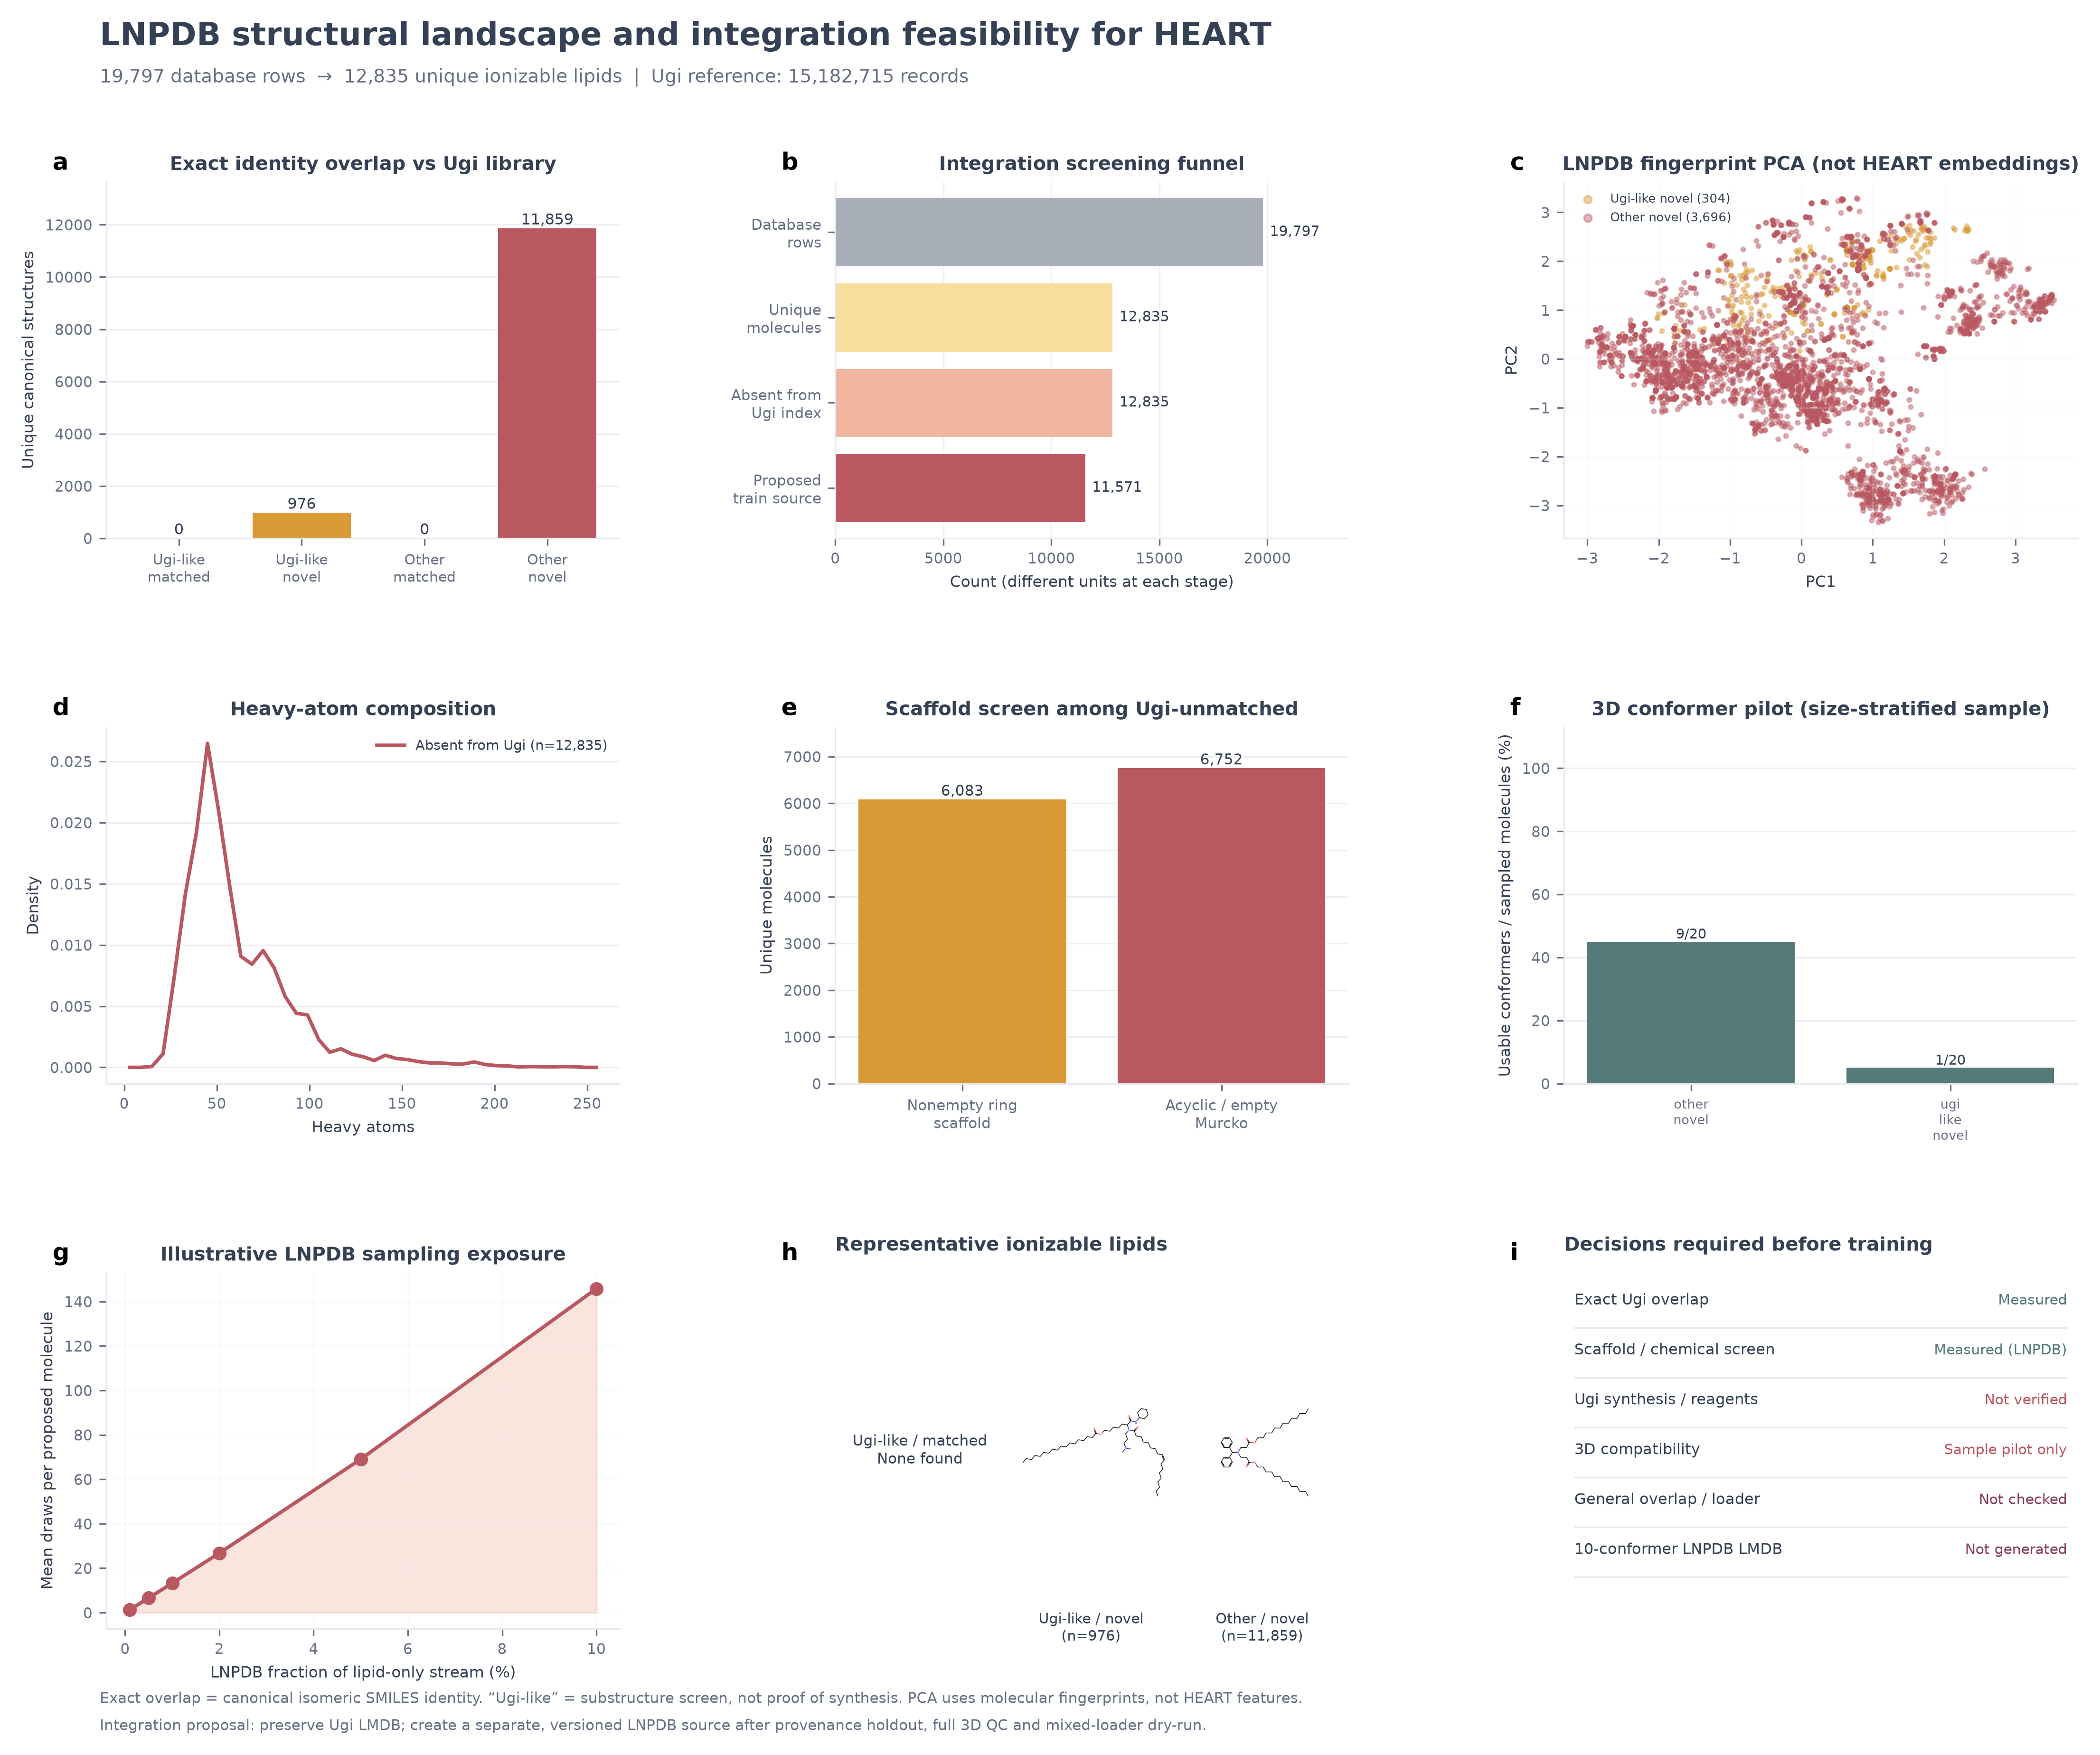

# HEART Priority 2 — LNPDB / Ugi-4CR Integration Feasibility

Generated (UTC): 2026-11-18T20:09:57.648732+00:00

## Verified sources

- LNPDB CSV: `/project/yli4/ypan/lipid_library/input/LNPDB.csv`
- LNPDB SHA-256: `c87319241a4beef9291e5dcd82020d74d3a6c4faa2672180ddcfbbb639f2f6c4`
- Priority-1 identity index: `/project/yli4/ypan/audits/ugi_priority1_interactive_evidence/cache/ugi_priority1_identity.sqlite3`
- Priority-1 scope: **FULL** (15,182,715 records)

## Full LNPDB molecular audit

- Raw LNPDB rows: **19,797**
- Unique neutral, canonical isomeric IL molecules: **12,835**
- Invalid raw IL SMILES rows: **0**; missing IL SMILES rows: **0**
- Ugi-like core by substructure screen: **976** (not proof of Ugi-4CR synthesis)
- Other structures: **11,859**
- Structures with >256 heavy atoms: **5**

## Exact overlap with the completed Ugi identity index

- Exact BLAKE2b-128 canonical identity matches: **0**
- Canonical identities absent from the Ugi index: **12,835**
- Matched in Ugi train: **0**; Ugi validation: **0**; both: **0**
- ugi_like_matched: **0**
- ugi_like_novel: **976**
- non_ugi_like_matched: **0**
- non_ugi_like_novel: **11,859**

## Structural feasibility, separate from synthesis provenance

- The Ugi-like designation is a broad substructure screen only; it neither proves reaction provenance nor confirms availability of the four required reagents.
- Molecules absent from the Ugi index may still overlap with the General pretrained dataset. This report does not resolve General/LNPDB overlap.
- Neutral and protonated representations were tracked separately; they were not silently merged into a different molecular identity.

## Stratified 3D-input compatibility pilot

- Pilot structures: **40**; molecules with usable 3D payload: **10**; skipped/failed: **30**.
- Requested conformers per pilot molecule: 2; heavy atom pilot limit: 256.
- This only tests representative ETKDG/RDKit input feasibility. Full 10-conformer production LMDB generation and production HEART loader/runtime checks are NOT performed.

## Pretraining integration decision

**Analysis status: ANALYSIS_COMPLETE_INTEGRATION_NOT_STARTED**

Recommended integration plan (not executed):
1. Preserve the original 15M Ugi LMDB and the General dataset unchanged.
2. Hold out a documented external LNPDB evaluation subset before training to avoid an optimistic downstream assessment.
3. Generate 3D conformers for the remaining eligible, novel LNPDB structures into a separate, versioned LMDB with Stage-06-compatible valid-slot metadata.
4. Extend the HEART mixed-sampling dataset loader to three named sources (General, Ugi, LNPDB) with explicit source weights and a source-specific validation split.
5. Benchmark matched-steps General+Ugi baseline vs. General+Ugi+LNPDB before claiming any performance benefit.

## Important limitations

- An exact matching negative is not proof of scaffold novelty; the Ugi index contains canonical hashes, not stored pairwise structural similarities.
- Molecular compatibility is not evidence of Ugi-4CR synthetic accessibility or successful RNA delivery.
- LNPDB includes assay/formulation metadata; experimental values are not self-supervised pretraining labels.
- These results are data-integration evidence, not permission to start HEART production training.

## Output files

- `summary.json` — numeric evidence and source fingerprints
- `lnpdb_unique_with_ugi_overlap.csv` — all unique canonical molecules with exact-match membership
- `lnpdb_ugi_matched.csv`, `lnpdb_ugi_novel.csv` — subsets
- `lnpdb_novel_pretraining_candidates.csv` — structural candidates; 3D data pending
- `3d_compatibility_pilot.csv` — measured representative coordinate feasibility
- `figures/` — plots with measured counts, not illustrative charts

## Integration feasibility tiers (proposed, not committed)

- NEW_LNPDB_SOURCE_3D_PENDING: **11,571** unique molecules
- EVALUATION_HOLDOUT_PROPOSED: **1,259** unique molecules
- STRUCTURE_QC_REVIEW: **5** unique molecules

### Scientific boundaries
- **Ugi-like structural motif is not sufficient to prove Ugi-4CR reagent compatibility.** Virtual reaction-library extension would require retrosynthetic decomposition and actual reagent mapping.
- **Exact unmatched is not scaffold novelty.** The available Ugi SQLite index contains canonical hashes, not a structure similarity index.
- **General pretraining overlap remains untested.** Pub-linked holdout is a proposal until provenance and General overlap are reviewed.
- **3D pilot is not full-LNPDB LMDB generation.** Full ETKDG/MMFF with 10 conformers, failure-aware Stage-06 sidecar and loader testing remain pending.
- **Recommended technical integration:** keep Ugi virtual library immutable; create a separately versioned LNPDB LMDB and use controlled General + Ugi + LNPDB sampling.
- Exclude known exact matched Ugi molecules from the incremental LNPDB training source. Protect Ugi validation molecules, and compare against the unchanged General+Ugi baseline.
- **Sampling scenarios** are exposure illustrations, not prescribed optimal weights; compare multiple source weights on the same downstream dataset.

### Additional evidence files
- `lnpdb_complete_integration_assessment.csv`
- `lnpdb_train_source_proposal_3d_pending.csv`
- `lnpdb_publication_holdout_proposal.csv`
- `lnpdb_ugi_like_novel_reagent_review.csv`
- `sampling_exposure_scenarios.csv`
- `fingerprint_pca_lnpdb_only.csv` (if PCA available)


In [4]:
# The only full-analysis entrypoint. Never runs in interactive SUBMIT mode.
if RUN_MODE == "analyze":
    from IPython.display import display, Image, Markdown
    from pathlib import Path
    options = Namespace(
        lnpdb=str(LNPDB_CSV),
        output=str(P2_RESULTS),
        ugi_index=str(UGI_SQLITE_INDEX) if UGI_SQLITE_INDEX else None,
        ugi_manifest=str(UGI_MANIFEST),
        priority1_report=str(P1_AUDIT / "03_full_molecular_audit.json"),
        pilot_per_group=int(PILOT_STRUCTURES_PER_GROUP),
        pilot_conformers=int(PILOT_CONFORMERS_PER_STRUCTURE),
        pilot_workers=int(PILOT_WORKERS),
        pilot_heavy_limit=int(MAX_HEAVY_ATOMS),
        max_eligible_heavy_atoms=int(MAX_HEAVY_ATOMS),
        seed=int(RANDOM_SEED),
    )
    run(options)
    summary_data = json.loads((P2_RESULTS / "summary.json").read_text())
    print("Exact Ugi overlap:", summary_data["overlap"]["total_matched"],
          "matched;", summary_data["overlap"]["total_novel"], "absent from Ugi index")
    print("Report:", P2_RESULTS / "integration_feasibility_report.md")
    display(Image(filename=str(P2_RESULTS / "figures/HEART_P2_research_composite.png")))
    display(Markdown((P2_RESULTS / "integration_feasibility_report.md").read_text(encoding="utf-8")))
else:
    print("Analysis intentionally skipped: Slurm job submitted in Section 1.")
